# SEEDS — Focus-Group Stakeholder Influence & Ability-to-Act Mapping
**ARC ARISE SEEDS · UAH · Task 1 (stakeholder pool) → Task 2 (spatial influence / ability, census capture)**

Pipeline
1. Load stakeholder pool CSV (`seeds_stakeholder_pool_v2.csv`) + vetted landowner candidates from `01b` parcel notebook
2. Pull 2020 Census blocks (POP20) + tracts + places for the 12-county AOI (TIGER/Line 2020)
3. Resolve each stakeholder's **footprint** (county / place / PAD-US unit / point+acres / parcel)
4. Area-weighted block capture → raw pop + % AOI / % event region / % tract
5. Score **Influence** (authority × population reach × constituency) and **Ability to Act** (6 weighted dimensions)
6. Per-stakeholder maps, AOI heat maps (influence, ability, coverage), interactive map
7. 8 event catchments (4 AL / 4 TN); round-robin greedy invite selection per event (influence + ability + marginal population coverage, sector quotas)
8. Everything → Google Drive `OUT_DIR`

Geometry upgrades without touching code: drop a PAD-US file at `PADUS_PATH` and/or a `geometry_overrides.geojson` (column `stakeholder_id`) for hunted parcels.

In [ ]:
# ---------------- PARAMETERS ----------------
SYNTHETIC = False                     # True = offline test with fake geometry
OUT_DIR   = '/content/drive/MyDrive/SEEDS/stakeholder_mapping'
POOL_CSV  = f'{OUT_DIR}/seeds_stakeholder_pool_v2.csv'   # upload Task-1 CSV here
LANDOWNER_CSV     = f'{OUT_DIR}/parcels/landowner_candidates.csv'      # from 01b parcel notebook (optional)
LANDOWNER_GEOJSON = f'{OUT_DIR}/parcels/landowner_parcels.geojson'     # parcel geometries keyed by stakeholder_id
INCLUDE_UNAPPROVED = False            # only rows with approved_for_invite == True (landowner vetting gate)
ELIG_SHARE = 0.10                     # stakeholder eligible for an event if >=10% of its captured pop is in that catchment
PADUS_PATH = None                     # e.g. f'{OUT_DIR}/padus/PADUS4_0_Geopackage.gpkg' (optional)
PADUS_LAYER = None                    # e.g. 'PADUS4_0Combined_Proclamation_Marine_Fee_Designation_Easement'
PADUS_NAME_FIELD = 'Unit_Nm'
GEOM_OVERRIDES = f'{OUT_DIR}/geometry_overrides.geojson' # optional: stakeholder_id + geometry (parcels etc.)
CENSUS_API_KEY = None                 # optional, for ACS tract enrichment
CACHE = '/content/cache'
CRS = 'EPSG:5070'                     # CONUS Albers (equal area)
MAKE_INDIVIDUAL_MAPS = True
PRIORITY_MAX = 3                      # include priority <= this

# Influence weights (sum = 1)
W_INF = dict(authority=0.40, reach=0.40, constituency=0.20)
# Ability-to-act weights (sum = 1); dims in CSV are 0-1, higher = fewer constraints
W_ABL = dict(d_control=0.25, d_approval=0.20, d_fiscal=0.15, d_authority=0.15, d_speed=0.10, d_freedom=0.15)

# Event design
ATTEND_TARGET = (20, 30)              # attendees per event
ATTEND_RATE   = 0.30                  # expected acceptance
SECTOR_MIN    = {'Local/Municipal': 4, 'State': 3, 'Federal': 2, 'Private Landowner': 2,
                 'Industry/Private Sector': 3, 'Nonprofit/Conservation': 3}

AOI = {'01089':'Madison AL','01095':'Marshall AL','01071':'Jackson AL',
       '47051':'Franklin TN','47031':'Coffee TN','47061':'Grundy TN','47115':'Marion TN',
       '47153':'Sequatchie TN','47007':'Bledsoe TN','47177':'Warren TN','47041':'DeKalb TN','47175':'Van Buren TN'}
# 8 events (4 per state). Blocks in counties shared by several events go to the nearest hub.
EVENTS = {
 'A1': dict(name='Huntsville Metro',                    counties=['01089'],                 hub=(34.730, -86.586)),
 'A2': dict(name='East Madison & Paint Rock Valley',    counties=['01089','01071','01095'], hub=(34.660, -86.320)),
 'A3': dict(name='Lake Guntersville & Sand Mountain',   counties=['01095'],                 hub=(34.358, -86.294)),
 'A4': dict(name='Scottsboro & NE Jackson',             counties=['01071'],                 hub=(34.672, -86.034)),
 'T1': dict(name='Highland Rim: Franklin + Coffee',     counties=['47051','47031'],         hub=(35.300, -86.140)),
 'T2': dict(name='South Cumberland: Grundy + Marion',   counties=['47061','47115'],         hub=(35.240, -85.800)),
 'T3': dict(name='Sequatchie & Fall Creek: Sequatchie + Bledsoe + Van Buren', counties=['47153','47007','47175'], hub=(35.500, -85.300)),
 'T4': dict(name='Caney Fork & Center Hill: Warren + DeKalb', counties=['47177','47041'],    hub=(35.680, -85.770)),
}

In [ ]:
import os, sys, math, json, re, urllib.request, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyogrio', 'mapclassify', 'folium', 'openpyxl'])
    from google.colab import drive
    drive.mount('/content/drive')
else:
    OUT_DIR = os.path.abspath(OUT_DIR.replace('/content/drive/MyDrive', './drive')); CACHE = './cache'
    _l = lambda p: os.path.abspath(p.replace('/content/drive/MyDrive', './drive'))
    POOL_CSV = _l(POOL_CSV) if os.path.exists(_l(POOL_CSV)) else './out/seeds_stakeholder_pool_v2.csv'
    GEOM_OVERRIDES, LANDOWNER_CSV, LANDOWNER_GEOJSON = map(_l, (GEOM_OVERRIDES, LANDOWNER_CSV, LANDOWNER_GEOJSON))
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box
from shapely.ops import unary_union
for d in [OUT_DIR, CACHE, f'{OUT_DIR}/maps/stakeholders', f'{OUT_DIR}/maps/heat', f'{OUT_DIR}/tables', f'{OUT_DIR}/gis']:
    os.makedirs(d, exist_ok=True)
print('OUT_DIR ->', OUT_DIR)

Mounted at /content/drive
OUT_DIR -> /content/drive/MyDrive/SEEDS/stakeholder_mapping


## 1 · Stakeholder pool

In [ ]:
pool = pd.read_csv(POOL_CSV, dtype={'counties_fips': str, 'geo_ref': str, 'lat': str, 'lon': str, 'approx_acres': str})
if os.path.exists(LANDOWNER_CSV):
    lo = pd.read_csv(LANDOWNER_CSV, dtype={'counties_fips': str, 'geo_ref': str, 'lat': str, 'lon': str, 'approx_acres': str})
    pool = pd.concat([pool, lo], ignore_index=True); print('landowner candidates merged:', len(lo))
pool['approved_for_invite'] = pool.get('approved_for_invite', True)
pool['approved_for_invite'] = pool.approved_for_invite.astype(str).str.lower().isin(['true', '1', 'yes', 'y'])
if not INCLUDE_UNAPPROVED: pool = pool[pool.approved_for_invite]
pool = pool[pool.priority <= PRIORITY_MAX].reset_index(drop=True)
print(len(pool), 'stakeholders'); display(pool.groupby(['sector']).size())

landowner candidates merged: 200
307 stakeholders


,0
sector,
Academic,23
Federal,41
Industry/Private Sector,29
Local/Municipal,102
Nonprofit/Conservation,35
Private Landowner,18
State,57
Tribal,2


## 2 · Census geography (2020 TIGER/Line blocks w/ POP20, tracts, places)

downloading https://www2.census.gov/geo/tiger/TIGER2020/TABBLOCK20/tl_2020_01_tabblock20.zip
downloading https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_01_tract.zip
downloading https://www2.census.gov/geo/tiger/TIGER2020/PLACE/tl_2020_01_place.zip
downloading https://www2.census.gov/geo/tiger/TIGER2020/TABBLOCK20/tl_2020_47_tabblock20.zip
downloading https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_47_tract.zip
downloading https://www2.census.gov/geo/tiger/TIGER2020/PLACE/tl_2020_47_place.zip
26,050 blocks · 200 tracts · AOI pop 779,313
{'A1': '366,349', 'A2': '30,164', 'A3': '93,072', 'A4': '48,759', 'T1': '100,663', 'T2': '42,366', 'T3': '36,907', 'T4': '61,033'}


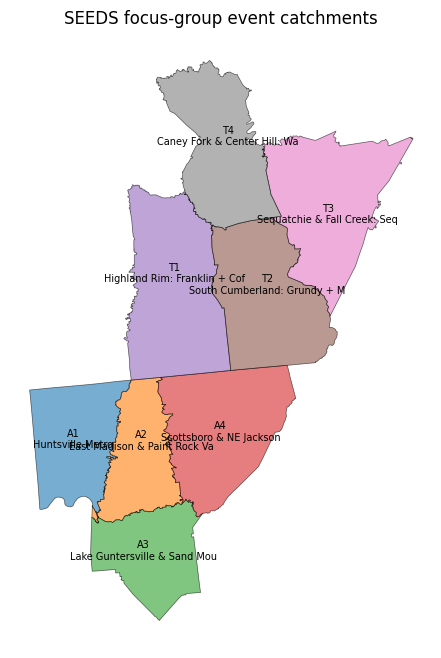

In [ ]:
TIGER = 'https://www2.census.gov/geo/tiger/TIGER2020'
def fetch(url):
    fp = os.path.join(CACHE, url.split('/')[-1])
    if not os.path.exists(fp):
        print('downloading', url); urllib.request.urlretrieve(url, fp)
    return fp

def load_census():
    blocks, tracts, places = [], [], []
    for st in sorted({k[:2] for k in AOI}):
        cos = ",".join(f"'{k[2:]}'" for k in AOI if k[:2] == st)
        b = gpd.read_file(fetch(f'{TIGER}/TABBLOCK20/tl_2020_{st}_tabblock20.zip'), where=f'COUNTYFP20 IN ({cos})')
        b = b.rename(columns={'GEOID20':'GEOID','POP20':'POP','HOUSING20':'HU'})
        b['cfips'] = b.STATEFP20 + b.COUNTYFP20; b['tract'] = b.GEOID.str[:11]
        blocks.append(b[['GEOID','tract','cfips','POP','HU','geometry']])
        t = gpd.read_file(fetch(f'{TIGER}/TRACT/tl_2020_{st}_tract.zip'), where=f'COUNTYFP IN ({cos})')
        t['cfips'] = t.STATEFP + t.COUNTYFP; tracts.append(t[['GEOID','cfips','NAMELSAD','geometry']])
        p = gpd.read_file(fetch(f'{TIGER}/PLACE/tl_2020_{st}_place.zip'))
        places.append(p[['STATEFP','NAME','NAMELSAD','GEOID','geometry']])
    B = pd.concat(blocks).to_crs(CRS); T = pd.concat(tracts).to_crs(CRS); P = pd.concat(places).to_crs(CRS)
    return gpd.GeoDataFrame(B, crs=CRS), gpd.GeoDataFrame(T, crs=CRS), gpd.GeoDataFrame(P, crs=CRS)

def synthetic_census(seed=0):
    # fake 12-county AOI: 30 km squares at approx. county centroids, 15x15 blocks each, 3x3 tracts
    rng = np.random.default_rng(seed)
    cen = {'01089':(34.76,-86.55),'01095':(34.37,-86.30),'01071':(34.78,-85.99),'47051':(35.15,-86.10),
           '47031':(35.49,-86.08),'47061':(35.39,-85.72),'47115':(35.13,-85.62),'47153':(35.37,-85.41),
           '47007':(35.60,-85.21),'47177':(35.68,-85.78),'47041':(35.98,-85.83),'47175':(35.70,-85.46)}
    pts = gpd.GeoSeries([Point(lo, la) for la, lo in cen.values()], crs=4326).to_crs(CRS)
    rows, n, s = [], 15, 30000
    for (cf, _), p in zip(cen.items(), pts):
        x0, y0 = p.x - s/2, p.y - s/2; d = s/n
        for i in range(n):
            for j in range(n):
                tr = f'{cf}{(i//5)*3 + j//5:06d}'
                pop = int(rng.lognormal(3, 1.2)) * (20 if cf == '01089' and 5 < i < 10 and 5 < j < 10 else 1)
                rows.append(dict(GEOID=f'{tr}{i*n+j:04d}', tract=tr, cfips=cf, POP=pop, HU=pop//2,
                                 geometry=box(x0+i*d, y0+j*d, x0+(i+1)*d, y0+(j+1)*d)))
    B = gpd.GeoDataFrame(rows, crs=CRS)
    T = B.dissolve('tract', as_index=False)[['tract','cfips','geometry']].rename(columns={'tract':'GEOID'}); T['NAMELSAD'] = 'Tract ' + T.GEOID.str[-6:]
    P = []
    for _, r in pool[pool.geo_type == 'place'].iterrows():
        for pr in r.geo_ref.split(';'):
            st, nm = pr.split(':', 1); cf = r.counties_fips.split(';')[0]
            c = B[B.cfips == cf].unary_union.centroid
            P.append(dict(STATEFP=st, NAME=nm, NAMELSAD=nm, GEOID=st + str(abs(hash(nm)) % 10**5),
                          geometry=Point(c.x + rng.uniform(-8e3, 8e3), c.y + rng.uniform(-8e3, 8e3)).buffer(rng.uniform(1500, 6000))))
    P = gpd.GeoDataFrame(P, crs=CRS).drop_duplicates(['STATEFP','NAME'])
    return B, T, P

blocks, tracts, places = synthetic_census() if SYNTHETIC else load_census()
blocks['barea'] = blocks.area
counties = blocks.dissolve('cfips', as_index=False)[['cfips','geometry']]; counties['name'] = counties.cfips.map(AOI)
AOI_GEOM = counties.unary_union
AOI_POP = blocks.POP.sum()
# assign every block to one event catchment
cen = blocks.geometry.representative_point().to_crs(4326)
bx, by = cen.x.values, cen.y.values
blocks['event'] = None; best = np.full(len(blocks), np.inf)
for ev, e in EVENTS.items():
    m = blocks.cfips.isin(e['counties']).values
    d = np.hypot((bx - e['hub'][1]) * np.cos(np.radians(e['hub'][0])), by - e['hub'][0])
    upd = m & (d < best); blocks.loc[upd, 'event'] = ev; best[upd] = d[upd]
REG_POP = blocks.groupby('event').POP.sum().to_dict()
catch = blocks.dissolve('event', as_index=False)[['event', 'geometry']]; catch['name'] = catch.event.map(lambda e: EVENTS[e]['name'])
TRACT_POP = blocks.groupby('tract').POP.sum()
print(f'{len(blocks):,} blocks · {len(tracts):,} tracts · AOI pop {AOI_POP:,}'); print({k: f'{v:,}' for k, v in REG_POP.items()})
fig, ax = plt.subplots(figsize=(9, 8)); catch.plot('event', ax=ax, cmap='tab10', alpha=.6, edgecolor='k', lw=.5)
for _, c in catch.iterrows():
    p = c.geometry.representative_point(); ax.annotate(f"{c.event}\n{c['name'][:28]}", (p.x, p.y), fontsize=7, ha='center')
ax.set_title('SEEDS focus-group event catchments'); ax.set_axis_off(); fig.savefig(f'{OUT_DIR}/maps/event_catchments.png', dpi=200); plt.show()

## 3 · Stakeholder footprints

In [ ]:
padus = None
if PADUS_PATH and os.path.exists(PADUS_PATH):
    bb = gpd.GeoSeries([AOI_GEOM.buffer(20000)], crs=CRS).to_crs(4326).total_bounds
    padus = gpd.read_file(PADUS_PATH, layer=PADUS_LAYER, bbox=tuple(bb)).to_crs(CRS)
    print('PAD-US units in AOI bbox:', len(padus))
_ov = [gpd.read_file(p).to_crs(CRS)[['stakeholder_id', 'geometry']] for p in (GEOM_OVERRIDES, LANDOWNER_GEOJSON) if os.path.exists(p)]
overrides = pd.concat(_ov).dissolve('stakeholder_id') if _ov else None

def _split(v): return [] if pd.isna(v) or str(v).strip() == '' else str(v).split('|')

def circle(lat, lon, acres):
    r = math.sqrt(float(acres) * 4046.86 / math.pi)
    return gpd.GeoSeries([Point(float(lon), float(lat))], crs=4326).to_crs(CRS).iloc[0].buffer(r)

def footprint(r):
    gt, ref = r.geo_type, str(r.geo_ref)
    if overrides is not None and r.stakeholder_id in overrides.index:
        return overrides.loc[r.stakeholder_id, 'geometry'], 'override'
    if gt == 'county':
        return counties[counties.cfips.isin(ref.split(';'))].unary_union, 'tiger_county'
    if gt == 'state_aoi':
        sel = counties if ref == 'ALL' else counties[counties.cfips.str[:2] == ref]
        return sel.unary_union, 'tiger_county'
    if gt == 'place':
        g = []
        for pr in ref.split(';'):
            st, nm = pr.split(':', 1)
            m = places[(places.STATEFP == st) & (places.NAME.str.lower() == nm.lower())]
            if len(m) == 0: print('  !! place not found:', pr)
            g += list(m.geometry)
        return (unary_union(g) if g else None), 'tiger_place'
    if gt in ('site', 'multi_site'):
        names, lats, lons, acs = ref.split('|'), _split(r.lat), _split(r.lon), _split(r.approx_acres)
        g, src = [], 'point_acres'
        if padus is not None:
            for i, nm in enumerate(names):
                m = padus[padus[PADUS_NAME_FIELD].fillna('').str.contains(re.escape(nm), case=False)]
                if len(m) and i < len(lats):
                    m = m[m.distance(circle(lats[i], lons[i], 1).centroid) < 50000]
                if len(m): g.append(m.unary_union); src = 'padus'
        if not g:
            g = [circle(la, lo, ac) for la, lo, ac in zip(lats, lons, acs)]
        return unary_union(g), src
    if gt == 'parcel_placeholder':
        c = counties[counties.cfips == ref.split(';')[0]].unary_union.representative_point()
        return c.buffer(math.sqrt(float(r.approx_acres) * 4046.86 / math.pi)), 'placeholder'
    if gt == 'override':
        print('  !! no geometry override for', r.stakeholder_id); return None, 'missing_override'
    raise ValueError(gt)

geoms, srcs = zip(*[footprint(r) for r in pool.itertuples()])
from shapely.geometry import Polygon
fp = gpd.GeoDataFrame(pool.copy(), geometry=[g if g is not None else Polygon() for g in geoms], crs=CRS); fp['geom_source'] = srcs
fp['geometry'] = fp.geometry.intersection(AOI_GEOM)          # clip to AOI
fp = fp[~fp.geometry.is_empty & fp.geometry.notna()].reset_index(drop=True)
fp['area_km2'] = fp.area / 1e6
n_cty = fp.counties_fips.str.count(';') + 1
fp['footprint_scale'] = np.select([fp.geo_type.isin(['site','multi_site','parcel_placeholder','place']), fp.geo_type == 'state_aoi', n_cty == 1],
                        ['local', 'state', 'county'], 'multi-county')
print(fp.geom_source.value_counts())

geom_source
tiger_county    226
tiger_place      49
point_acres      32
Name: count, dtype: int64


## 4 · Block-level population capture (area-weighted)

In [ ]:
sidx = blocks.sindex
W = []
for r in fp.itertuples():
    if r.geom_source == 'tiger_county':     # exact membership, no overlay needed
        idx = np.where(blocks.cfips.isin(r.counties_fips.split(';') if r.geo_type == 'county' else
                       counties[counties.intersects(r.geometry.buffer(-10))].cfips))[0]
        frac = np.ones(len(idx))
    else:
        idx = sidx.query(r.geometry, predicate='intersects')
        frac = blocks.geometry.iloc[idx].intersection(r.geometry).area.values / blocks.barea.values[idx]
    W.append(pd.DataFrame({'stakeholder_id': r.stakeholder_id, 'bidx': idx, 'frac': np.clip(frac, 0, 1)}))
W = pd.concat(W, ignore_index=True)
W = W[W.frac > 1e-4]
W['GEOID'] = blocks.GEOID.values[W.bidx]; W['tract'] = blocks.tract.values[W.bidx]; W['cfips'] = blocks.cfips.values[W.bidx]
W['pop_w'] = blocks.POP.values[W.bidx] * W.frac
W['event'] = blocks.event.values[W.bidx]
print(f'{len(W):,} stakeholder×block links')

1,316,305 stakeholder×block links


## 5 · Influence & Ability-to-Act scoring

,stakeholder_id,org,poc_name,sector,event_final,footprint_scale,geom_source,area_km2,pop_captured,pct_AOI_pop,pct_event_region_pop,n_tracts,influence,influence_tier,ability,ability_tier,quadrant
36,SEEDS2-037,Madison County Commission,Rex Vaughn,Local/Municipal,A1,county,tiger_county,2104.923,388153.0,49.807,100.000,95,0.979,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
63,SEEDS2-064,Marshall County Commission,Ashleigh Bubbett,Local/Municipal,A3,county,tiger_county,1614.027,97612.0,12.525,100.000,26,0.939,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
75,SEEDS2-076,Marshall County Commission,John Young,Local/Municipal,A3,county,tiger_county,1614.027,97612.0,12.525,100.000,26,0.939,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
154,SEEDS2-155,Coffee County (TN) Government,Dennis Hunt,Local/Municipal,T1,county,tiger_county,1125.490,57889.0,7.428,57.508,17,0.923,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
94,SEEDS2-095,Jackson County Commission,TBD - verify,Local/Municipal,A4,county,tiger_county,2918.380,52579.0,6.747,100.000,16,0.921,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
155,SEEDS2-156,Franklin County (TN) Government,Chris Guess,Local/Municipal,T1,county,tiger_county,1491.188,42774.0,5.489,42.492,10,0.914,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
304,SEEDS2-305,Warren County (TN) Government,Terry Bell,Local/Municipal,T4,county,tiger_county,1124.144,40953.0,5.255,67.100,10,0.913,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
211,SEEDS2-212,Marion County (TN) Government,David Jackson Jr.,Local/Municipal,T2,county,tiger_county,1326.958,28837.0,3.700,68.066,7,0.903,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
303,SEEDS2-304,DeKalb County (TN) Government,Patrick Ray,Local/Municipal,T4,county,tiger_county,852.070,20080.0,2.577,32.900,5,0.892,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
260,SEEDS2-261,Sequatchie County Government,Keith Cartwright,Local/Municipal,T3,county,tiger_county,689.049,15826.0,2.031,42.881,4,0.885,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)


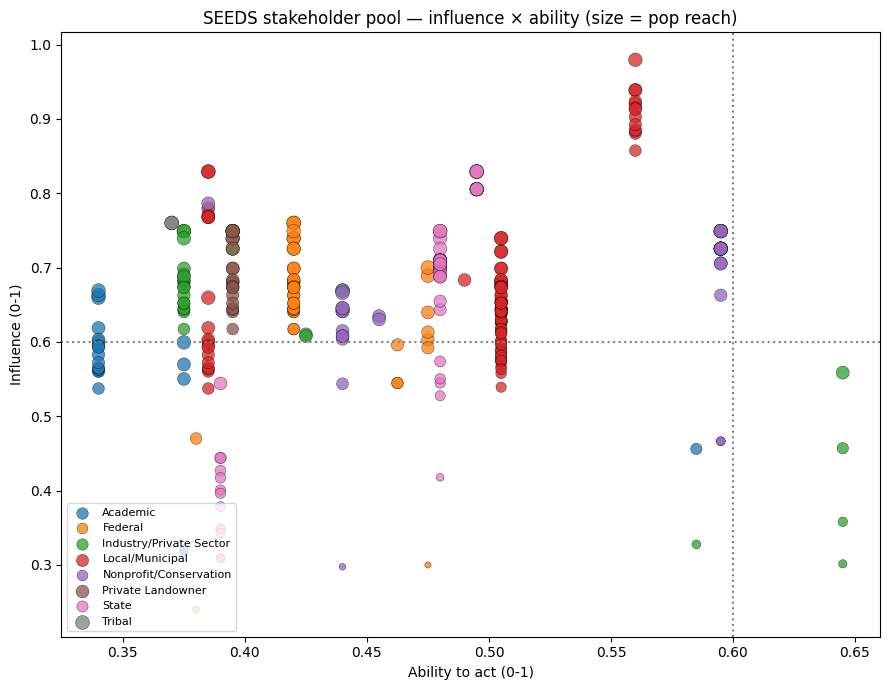

In [ ]:
cap = W.groupby('stakeholder_id').agg(pop_captured=('pop_w','sum'), n_blocks=('GEOID','nunique'), n_tracts=('tract','nunique'))
fp = fp.drop(columns=[c for c in cap.columns if c in fp], errors='ignore').merge(cap, left_on='stakeholder_id', right_index=True, how='left').fillna({'pop_captured':0,'n_blocks':0,'n_tracts':0})
fp['pct_AOI_pop'] = 100 * fp.pop_captured / AOI_POP
ev_pop = W.groupby(['stakeholder_id', 'event']).pop_w.sum().unstack(fill_value=0)
ev_area = W.assign(a=W.frac * blocks.barea.values[W.bidx]).groupby(['stakeholder_id', 'event']).a.sum().unstack(fill_value=0)
share = ev_pop.div(ev_pop.sum(1).replace(0, np.nan), axis=0).fillna(ev_area.div(ev_area.sum(1), axis=0))
fp['event_auto'] = fp.stakeholder_id.map(share.idxmax(1))
fp['event_final'] = np.where(fp.event_region.isin(EVENTS.keys()), fp.event_region, fp.event_auto)
fp['eligible_events'] = fp.stakeholder_id.map(share.apply(lambda r: ';'.join(r.index[r >= ELIG_SHARE]), axis=1)).fillna('')
fp['eligible_events'] = [';'.join(sorted(set(filter(None, (e + ';' + f).split(';'))))) for e, f in zip(fp.eligible_events, fp.event_final)]
fp['pct_event_region_pop'] = [100 * ev_pop.at[s, e] / REG_POP[e] if s in ev_pop.index and e in ev_pop.columns else 0
                              for s, e in zip(fp.stakeholder_id, fp.event_final)]
fp['reach'] = np.log10(1 + fp.pop_captured) / np.log10(1 + AOI_POP)
fp['influence'] = (W_INF['authority'] * fp.authority / 5 + W_INF['reach'] * fp.reach + W_INF['constituency'] * fp.constituency)
fp['ability'] = sum(w * fp[d] for d, w in W_ABL.items())
for k in ['influence', 'ability']:
    fp[f'{k}_rank_1to5'] = (1 + 4 * fp[k]).round(2)
    fp[f'{k}_tier'] = pd.cut(fp[k], [-1, 0.40, 0.60, 2], labels=['Low', 'Medium', 'High'])
fp['quadrant'] = np.select([(fp.influence >= .6) & (fp.ability >= .6), (fp.influence >= .6), (fp.ability >= .6)],
                           ['High-Inf/High-Act (decision partner)', 'High-Inf/Low-Act (convener/legitimizer)',
                            'Low-Inf/High-Act (implementer)'], 'Low-Inf/Low-Act (informant)')
cols = ['stakeholder_id','org','poc_name','sector','event_final','footprint_scale','geom_source','area_km2','pop_captured','pct_AOI_pop','pct_event_region_pop',
        'n_tracts','influence','influence_tier','ability','ability_tier','quadrant']
display(fp[cols].sort_values('influence', ascending=False).head(15).round(3))

# influence vs ability scatter
fig, ax = plt.subplots(figsize=(9, 7))
for s, g in fp.groupby('sector'):
    ax.scatter(g.ability, g.influence, s=20 + 80 * g.reach, label=s, alpha=.75, edgecolor='k', lw=.3)
ax.axhline(.6, c='grey', ls=':'); ax.axvline(.6, c='grey', ls=':')
ax.set(xlabel='Ability to act (0-1)', ylabel='Influence (0-1)', title='SEEDS stakeholder pool — influence × ability (size = pop reach)')
ax.legend(fontsize=8, loc='lower left'); fig.tight_layout(); fig.savefig(f'{OUT_DIR}/maps/influence_ability_scatter.png', dpi=200); plt.show()

## 6 · Census capture tables (stakeholder, stakeholder × tract, stakeholder × county)

In [ ]:
st_tr = (W.groupby(['stakeholder_id','tract']).pop_w.sum().rename('pop_captured').reset_index())
st_tr['tract_pop'] = st_tr.tract.map(TRACT_POP); st_tr['pct_of_tract'] = 100 * st_tr.pop_captured / st_tr.tract_pop.replace(0, np.nan)
st_tr = st_tr.merge(fp[['stakeholder_id','org','poc_name','sector','event_final']], on='stakeholder_id')
cpop = blocks.groupby('cfips').POP.sum()
st_co = W.groupby(['stakeholder_id','cfips']).pop_w.sum().rename('pop_captured').reset_index()
st_co['county'] = st_co.cfips.map(AOI); st_co['pct_of_county'] = 100 * st_co.pop_captured / st_co.cfips.map(cpop)
st_co_wide = st_co.pivot_table(index='stakeholder_id', columns='county', values='pct_of_county', fill_value=0).round(2)

summary = fp.drop(columns='geometry').sort_values(['event_final','influence'], ascending=[True, False])
summary.round(4).to_csv(f'{OUT_DIR}/tables/stakeholder_scores_capture.csv', index=False)
st_tr.round(3).to_csv(f'{OUT_DIR}/tables/stakeholder_x_tract.csv', index=False)
st_co.round(3).to_csv(f'{OUT_DIR}/tables/stakeholder_x_county.csv', index=False)
display(summary[cols].head(10).round(3))

,stakeholder_id,org,poc_name,sector,event_final,footprint_scale,geom_source,area_km2,pop_captured,pct_AOI_pop,pct_event_region_pop,n_tracts,influence,influence_tier,ability,ability_tier,quadrant
36,SEEDS2-037,Madison County Commission,Rex Vaughn,Local/Municipal,A1,county,tiger_county,2104.923,388153.0,49.807,100.0,95,0.979,High,0.560,Medium,High-Inf/Low-Act (convener/legitimizer)
14,SEEDS2-015,Top of Alabama Regional Council of Governments...,Michelle Gilliam Jordan,Local/Municipal,A1,multi-county,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.385,Low,High-Inf/Low-Act (convener/legitimizer)
15,SEEDS2-016,Top of Alabama Regional Council of Governments...,Leslie Wright,Local/Municipal,A1,multi-county,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.385,Low,High-Inf/Low-Act (convener/legitimizer)
20,SEEDS2-021,ADECA - Appalachian Regional Commission State ...,TBD - verify,State,A1,state,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.495,Medium,High-Inf/Low-Act (convener/legitimizer)
23,SEEDS2-024,AL DCNR State Lands Division - Forever Wild La...,TBD - verify,State,A1,state,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.495,Medium,High-Inf/Low-Act (convener/legitimizer)
35,SEEDS2-036,Alabama Tourism Department,TBD - verify,State,A1,state,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.495,Medium,High-Inf/Low-Act (convener/legitimizer)
37,SEEDS2-038,AL DCNR - State Parks Division,Matthew Capps,State,A1,state,tiger_county,6637.330,538344.0,69.079,100.0,137,0.829,High,0.495,Medium,High-Inf/Low-Act (convener/legitimizer)
24,SEEDS2-025,Cherokee Nation - Tribal Historic Preservation...,TBD - verify,Tribal,A1,state,tiger_county,15946.399,779313.0,100.000,100.0,200,0.760,High,0.370,Low,High-Inf/Low-Act (convener/legitimizer)
25,SEEDS2-026,Eastern Band of Cherokee Indians - Tribal Hist...,TBD - verify,Tribal,A1,state,tiger_county,15946.399,779313.0,100.000,100.0,200,0.760,High,0.370,Low,High-Inf/Low-Act (convener/legitimizer)
27,SEEDS2-028,"NPS Rivers, Trails & Conservation Assistance (...",TBD - verify,Federal,A1,state,tiger_county,15946.399,779313.0,100.000,100.0,200,0.760,High,0.420,Medium,High-Inf/Low-Act (convener/legitimizer)


## 7 · AOI heat maps — influence, ability, coverage

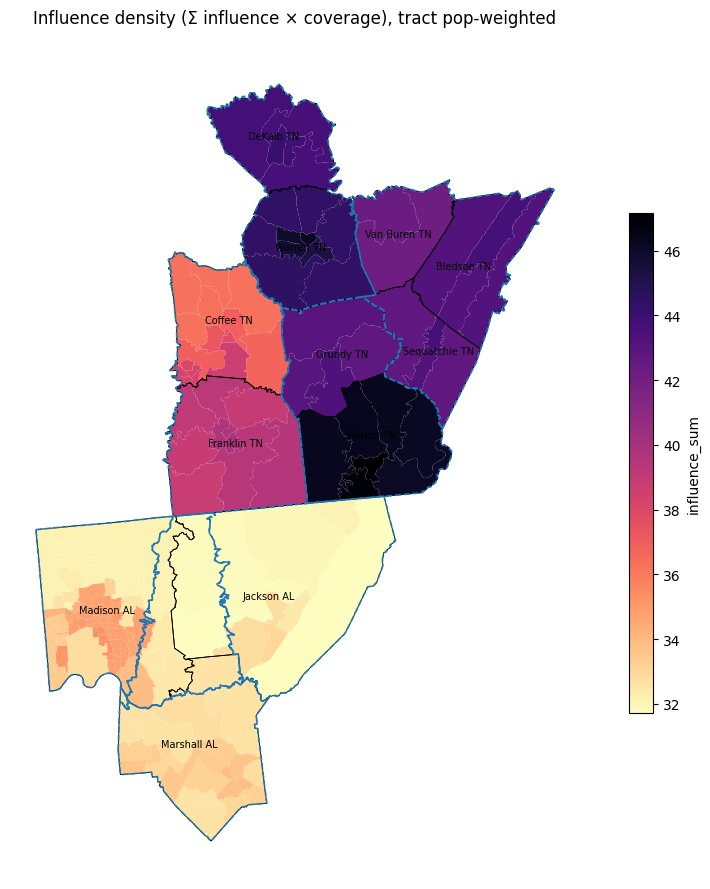

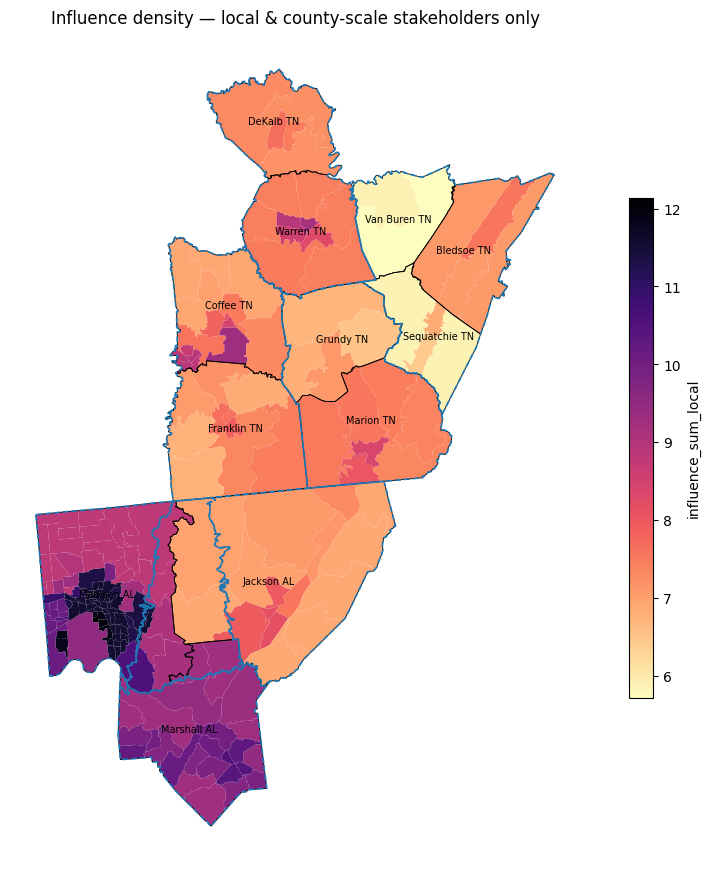

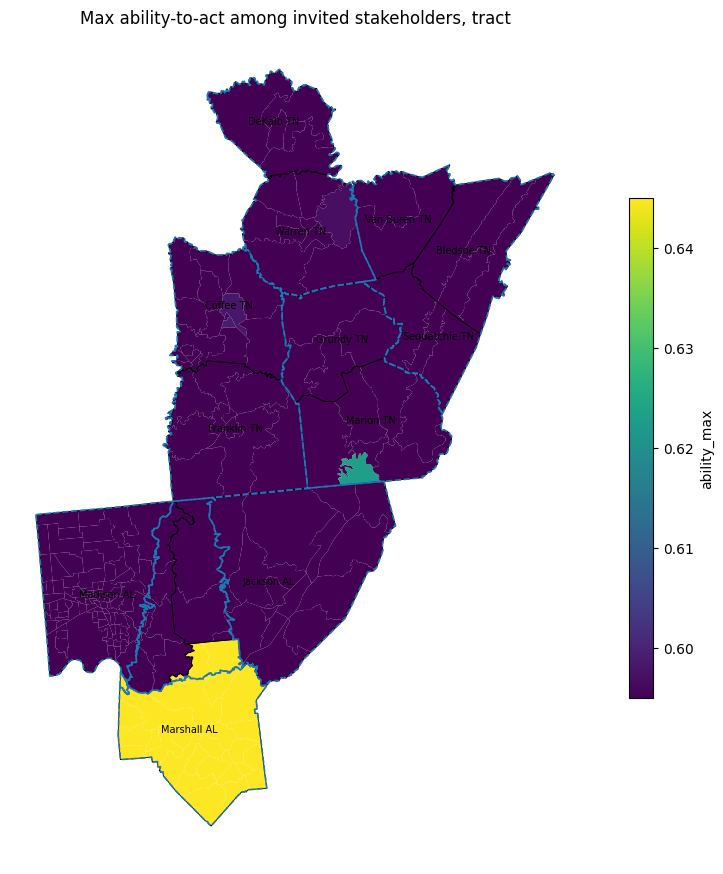

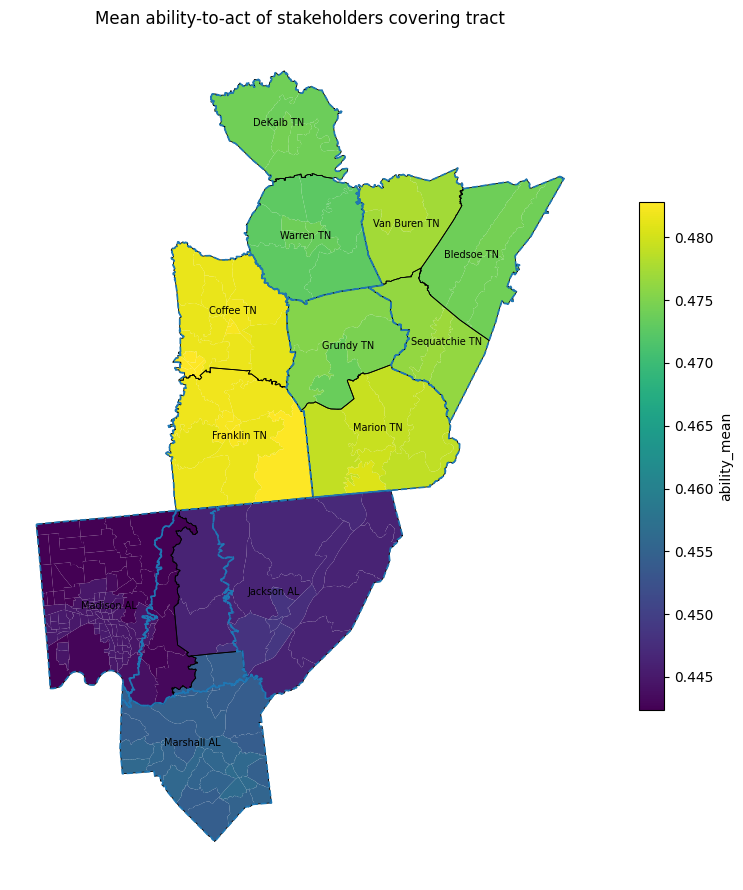

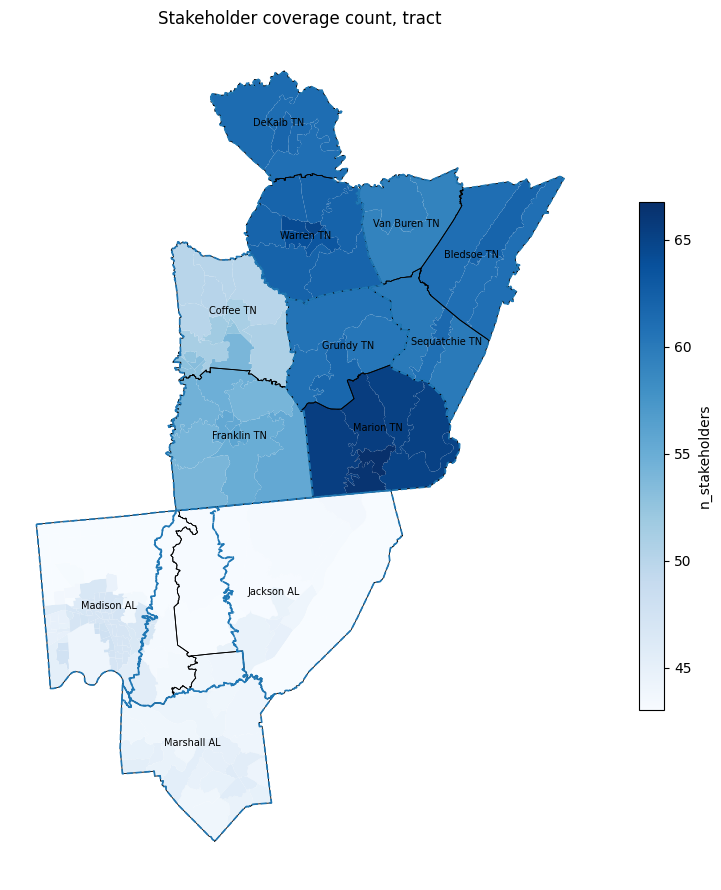

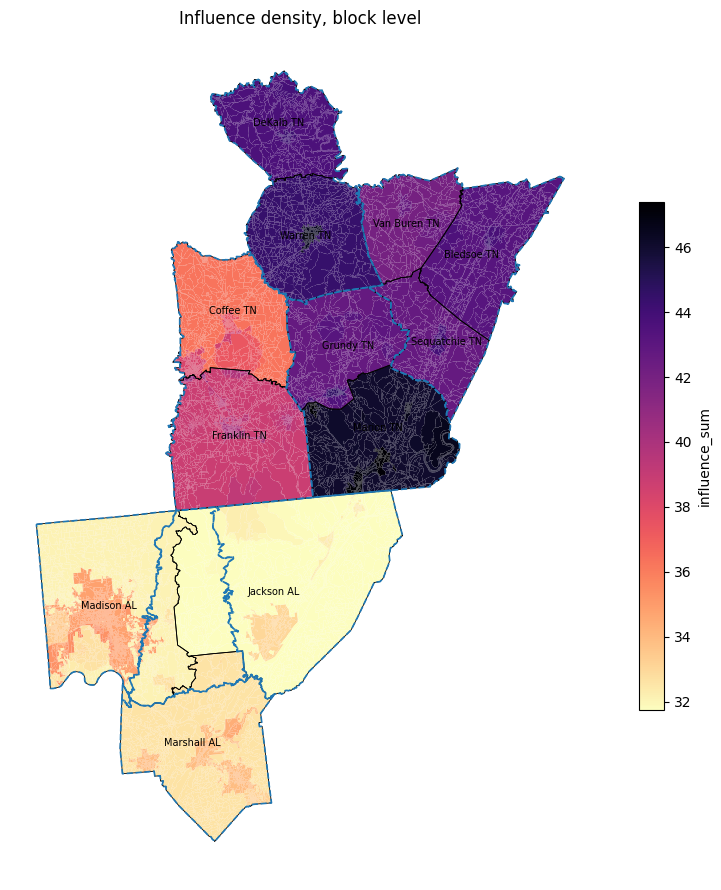

In [ ]:
S = fp.set_index('stakeholder_id')
Wb = W.join(S[['influence','ability']], on='stakeholder_id')
Wb['inf_w'] = Wb.influence * Wb.frac
Wb['inf_w_local'] = Wb.inf_w * Wb.stakeholder_id.map(S.footprint_scale).isin(['local', 'county'])
blk = blocks[['GEOID','tract','cfips','POP','geometry']].copy()
agg = Wb.groupby('GEOID').agg(influence_sum=('inf_w','sum'), influence_sum_local=('inf_w_local','sum'), influence_max=('influence','max'),
                             ability_max=('ability','max'), ability_mean=('ability','mean'), n_stakeholders=('stakeholder_id','nunique'))
# high-ability coverage: n stakeholders with ability >= .6 touching block
agg['n_high_ability'] = Wb[Wb.ability >= .6].groupby('GEOID').stakeholder_id.nunique()
blk = blk.merge(agg, left_on='GEOID', right_index=True, how='left').fillna(0)

def popw(g, c):
    w = g.POP if g.POP.sum() > 0 else pd.Series(1, index=g.index)
    return np.average(g[c], weights=w)
mets = ['influence_sum','influence_sum_local','influence_max','ability_max','ability_mean','n_stakeholders','n_high_ability']
trt = blk.groupby('tract').apply(lambda g: pd.Series({c: popw(g, c) for c in mets} | {'POP': g.POP.sum()}))
trt = tracts.merge(trt, left_on='GEOID', right_index=True)

def heat(gdf, col, title, cmap, fn):
    fig, ax = plt.subplots(figsize=(10, 9))
    gdf.plot(col, ax=ax, cmap=cmap, legend=True, linewidth=0, legend_kwds={'shrink': .6, 'label': col})
    counties.boundary.plot(ax=ax, color='k', lw=.6); catch.boundary.plot(ax=ax, color='#1f77b4', lw=1.2, ls='--')
    for _, c in counties.iterrows():
        p = c.geometry.representative_point(); ax.annotate(c['name'], (p.x, p.y), fontsize=7, ha='center')
    ax.set_title(title); ax.set_axis_off(); fig.tight_layout(); fig.savefig(fn, dpi=200); plt.show()

heat(trt, 'influence_sum', 'Influence density (Σ influence × coverage), tract pop-weighted', 'magma_r', f'{OUT_DIR}/maps/heat/heat_influence_tract.png')
heat(trt, 'influence_sum_local', 'Influence density — local & county-scale stakeholders only', 'magma_r', f'{OUT_DIR}/maps/heat/heat_influence_local_tract.png')
heat(trt, 'ability_max', 'Max ability-to-act among invited stakeholders, tract', 'viridis', f'{OUT_DIR}/maps/heat/heat_ability_max_tract.png')
heat(trt, 'ability_mean', 'Mean ability-to-act of stakeholders covering tract', 'viridis', f'{OUT_DIR}/maps/heat/heat_ability_mean_tract.png')
heat(trt, 'n_stakeholders', 'Stakeholder coverage count, tract', 'Blues', f'{OUT_DIR}/maps/heat/heat_coverage_tract.png')
heat(blk, 'influence_sum', 'Influence density, block level', 'magma_r', f'{OUT_DIR}/maps/heat/heat_influence_block.png')

## 8 · Per-stakeholder maps (influence footprint + ability)

In [ ]:
def stakeholder_map(r, ax):
    counties.plot(ax=ax, color='#f2f2f2', edgecolor='#999', lw=.4)
    gpd.GeoSeries([r.geometry], crs=CRS).plot(ax=ax, color=plt.cm.magma_r(.15 + .8 * r.influence), edgecolor='k', lw=.5, alpha=.85)
    ax.set_title(f"{r.stakeholder_id} · {r.org[:48]}\n{str(r.poc_name)[:30]}\nInf {r.influence:.2f} ({r.influence_tier}) · Act {r.ability:.2f} ({r.ability_tier})\n"
                 f"pop {r.pop_captured:,.0f} · {r.pct_AOI_pop:.2f}% AOI · {r.pct_event_region_pop:.1f}% region", fontsize=6.5)
    ax.set_axis_off()

for ev, g in fp.groupby('event_final'):      # contact sheets per event
    n = len(g); nc = 6; nr = math.ceil(n / nc)
    fig, axs = plt.subplots(nr, nc, figsize=(nc * 3.2, nr * 3.4)); axs = np.atleast_1d(axs).ravel()
    for ax, r in zip(axs, g.sort_values('influence', ascending=False).itertuples()): stakeholder_map(r, ax)
    for ax in axs[n:]: ax.set_axis_off()
    fig.suptitle(f'{ev} stakeholder footprints', fontsize=12); fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/maps/stakeholders/sheet_{ev}.png', dpi=160); plt.close(fig)
if MAKE_INDIVIDUAL_MAPS:
    for r in fp.itertuples():
        fig, ax = plt.subplots(figsize=(5, 5)); stakeholder_map(r, ax); fig.tight_layout()
        fig.savefig(f'{OUT_DIR}/maps/stakeholders/{r.stakeholder_id}.png', dpi=130); plt.close(fig)
print('stakeholder maps written')

stakeholder maps written


## 9 · Invite selection per event (greedy: influence + ability + marginal population coverage, sector quotas)

In [ ]:
n_inv = math.ceil(ATTEND_TARGET[1] / ATTEND_RATE)
print(f'Target {ATTEND_TARGET} attendees/event @ {ATTEND_RATE:.0%} acceptance -> {math.ceil(ATTEND_TARGET[0]/ATTEND_RATE)}-{n_inv} invites/event; '
      f'{len(EVENTS)} events -> {len(EVENTS)*math.ceil(ATTEND_TARGET[0]/ATTEND_RATE)}-{len(EVENTS)*n_inv} total; pool = {len(fp)}')
if len(fp) < len(EVENTS) * n_inv: print('!! pool smaller than invite target -> output is a full ranked assignment; add landowners (01b) or raise ATTEND_RATE')
bpop = blocks.set_index('GEOID').POP
cov = {ev: pd.Series(0.0, index=blocks.GEOID[blocks.event == ev].values) for ev in EVENTS}
need = {ev: dict(SECTOR_MIN) for ev in EVENTS}
Wg = {ev: W[W.event == ev] for ev in EVENTS}
elig = {s: set(e.split(';')) for s, e in zip(fp.stakeholder_id, fp.eligible_events)}
S = fp.set_index('stakeholder_id'); chosen = set(); rows = []
def score(ev, sid, w=(0.35, 0.30, 0.35)):
    r = S.loc[sid]; ws = Wg[ev][Wg[ev].stakeholder_id == sid].set_index('GEOID').frac
    c0 = cov[ev].reindex(ws.index).fillna(0)
    gain = ((np.minimum(1, c0 + ws) - c0) * bpop.reindex(ws.index)).sum() / REG_POP[ev]
    home = 0.15 if r.event_final == ev else 0
    return w[0] * r.influence + w[1] * r.ability + w[2] * min(1, gain * 3) + home + (1.0 if need[ev].get(r.sector, 0) > 0 else 0), gain
counts = {ev: 0 for ev in EVENTS}
while True:                                  # round-robin across events -> balanced invite lists
    progressed = False
    for ev in EVENTS:
        if counts[ev] >= n_inv: continue
        cands = [s for s in S.index if s not in chosen and ev in elig[s]]
        if not cands: continue
        sc = {s: score(ev, s) for s in cands}; best = max(sc, key=lambda s: sc[s][0]); r = S.loc[best]
        ws = Wg[ev][Wg[ev].stakeholder_id == best].set_index('GEOID').frac
        cov[ev].loc[ws.index] = np.minimum(1, cov[ev].loc[ws.index] + ws)
        need[ev][r.sector] = need[ev].get(r.sector, 0) - 1; chosen.add(best); counts[ev] += 1; progressed = True
        rows.append(dict(event=ev, event_name=EVENTS[ev]['name'], invite_rank=counts[ev], stakeholder_id=best, org=r.org,
                         poc_name=r.get('poc_name', ''), poc_role=r.get('poc_role', ''), poc_email=r.get('poc_email', ''),
                         sector=r.sector, influence=r.influence, ability=r.ability, marginal_pop_gain_pct=100 * sc[best][1],
                         cum_event_pop_covered_pct=100 * (cov[ev] * bpop.reindex(cov[ev].index)).sum() / REG_POP[ev]))
    if not progressed: break
invites = pd.DataFrame(rows)
invites.round(3).to_csv(f'{OUT_DIR}/tables/invite_list_by_event.csv', index=False)
display(invites.groupby('event').agg(n=('stakeholder_id','size'), final_cov=('cum_event_pop_covered_pct','max')))
display(invites.pivot_table(index='sector', columns='event', values='stakeholder_id', aggfunc='count', fill_value=0))

Target (20, 30) attendees/event @ 30% acceptance -> 67-100 invites/event; 8 events -> 536-800 total; pool = 307
!! pool smaller than invite target -> output is a full ranked assignment; add landowners (01b) or raise ATTEND_RATE


,n,final_cov
event,,
A1,35,100.0
A2,11,100.0
A3,30,100.0
A4,20,100.0
T1,60,100.0
T2,55,100.0
T3,52,100.0
T4,44,100.0


event,A1,A2,A3,A4,T1,T2,T3,T4
sector,,,,,,,,
Academic,2,2,2,1,4,4,4,4
Federal,7,1,3,3,10,5,6,6
Industry/Private Sector,4,0,4,1,3,6,4,7
Local/Municipal,10,2,12,8,20,17,17,16
Nonprofit/Conservation,3,4,1,2,6,12,4,3
Private Landowner,2,0,3,3,3,2,3,2
State,5,2,5,2,14,9,14,6
Tribal,2,0,0,0,0,0,0,0


## 10 · Proxy representation summary (sector × event, union pop captured)

In [ ]:
rows = []
for (ev, sec), g in fp.groupby(['event_final', 'sector']):
    ww = W[W.stakeholder_id.isin(g.stakeholder_id) & (W.event == ev)]
    u = ww.groupby('GEOID').frac.max()                       # union (no double count)
    p = (u * blocks.set_index('GEOID').POP.reindex(u.index)).sum()
    gl = g[g.footprint_scale.isin(['local', 'county'])]                 # exclude multi-county/state orgs (trivially 100%)
    ul = W[W.stakeholder_id.isin(gl.stakeholder_id) & (W.event == ev)].groupby('GEOID').frac.max()
    pl = (ul * blocks.set_index('GEOID').POP.reindex(ul.index)).sum()
    eff = (g.set_index('stakeholder_id').constituency * W[W.stakeholder_id.isin(g.stakeholder_id) & (W.event == ev)]
           .groupby('stakeholder_id').pop_w.sum()).sum()
    rows.append(dict(event_region=ev, sector=sec, n=len(g), n_local_county=len(gl), union_pop=round(p), pct_region_pop=100 * p / REG_POP[ev],
                     union_pop_local_county=round(pl), pct_region_pop_local_county=100 * pl / REG_POP[ev],
                     effective_pop_represented=round(eff), mean_influence=g.influence.mean(), mean_ability=g.ability.mean()))
proxy = pd.DataFrame(rows).round(3); proxy.to_csv(f'{OUT_DIR}/tables/proxy_sector_by_event.csv', index=False)
print('% event-region population captured by local + county-scale stakeholders (union, no double count):')
display(proxy.pivot(index='sector', columns='event_region', values='pct_region_pop_local_county').round(1))

% event-region population captured by local + county-scale stakeholders (union, no double count):


event_region,A1,A2,A3,A4,T1,T2,T3,T4
sector,,,,,,,,
Academic,100.0,0.1,100.0,100.0,100.0,100.0,100.0,100.0
Federal,100.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0
Industry/Private Sector,100.0,NaN,100.0,100.0,100.0,100.0,100.0,100.0
Local/Municipal,100.0,12.3,100.0,100.0,100.0,100.0,100.0,100.0
Nonprofit/Conservation,55.7,0.0,NaN,0.0,4.3,68.1,0.0,0.0
Private Landowner,100.0,NaN,100.0,100.0,100.0,100.0,100.0,100.0
State,100.0,0.0,100.0,0.0,1.6,7.1,42.1,0.1
Tribal,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 11 · Optional ACS tract enrichment (income, poverty) — needs internet; key optional

In [ ]:
try:
    if SYNTHETIC: raise RuntimeError('skip in synthetic mode')
    import requests
    acs = []
    for cf in AOI:
        q = dict(get='NAME,B01003_001E,B19013_001E,B17001_002E', **{'for': 'tract:*', 'in': f'state:{cf[:2]} county:{cf[2:]}'})
        if CENSUS_API_KEY: q['key'] = CENSUS_API_KEY
        j = requests.get('https://api.census.gov/data/2022/acs/acs5', params=q, timeout=60).json()
        acs.append(pd.DataFrame(j[1:], columns=j[0]))
    acs = pd.concat(acs); acs['GEOID'] = acs.state + acs.county + acs.tract
    acs = acs.rename(columns={'B01003_001E':'acs_pop','B19013_001E':'med_hh_income','B17001_002E':'pop_poverty'})
    for c in ['acs_pop','med_hh_income','pop_poverty']: acs[c] = pd.to_numeric(acs[c]).where(lambda s: s >= 0)
    trt = trt.merge(acs[['GEOID','acs_pop','med_hh_income','pop_poverty']], on='GEOID', how='left')
    st_tr = st_tr.merge(acs[['GEOID','med_hh_income','pop_poverty','acs_pop']], left_on='tract', right_on='GEOID', how='left').drop(columns='GEOID')
    st_tr['pop_poverty_captured'] = st_tr.pop_poverty * st_tr.pct_of_tract / 100
    st_tr.round(3).to_csv(f'{OUT_DIR}/tables/stakeholder_x_tract.csv', index=False)
    print('ACS joined')
except Exception as e:
    print('ACS skipped:', e)

## 12 · GIS exports + interactive map

In [14]:
fp_out = fp.copy(); fp_out[['influence_tier','ability_tier']] = fp_out[['influence_tier','ability_tier']].astype(str)
for c in fp_out.columns:
    if c != 'geometry' and fp_out[c].dtype == object: fp_out[c] = fp_out[c].astype(str)
catch.to_file(f'{OUT_DIR}/gis/seeds_stakeholders.gpkg', layer='event_catchments', driver='GPKG')
fp_out.to_crs(4326).to_file(f'{OUT_DIR}/gis/stakeholder_footprints.geojson', driver='GeoJSON')
fp_out.to_file(f'{OUT_DIR}/gis/seeds_stakeholders.gpkg', layer='footprints', driver='GPKG')
trt.to_file(f'{OUT_DIR}/gis/seeds_stakeholders.gpkg', layer='tract_heat', driver='GPKG')
blk.to_file(f'{OUT_DIR}/gis/seeds_stakeholders.gpkg', layer='block_heat', driver='GPKG')
with pd.ExcelWriter(f'{OUT_DIR}/tables/SEEDS_stakeholder_mapping.xlsx') as xw:
    summary.round(4).to_excel(xw, 'scores_capture', index=False); invites.round(3).to_excel(xw, 'invites', index=False)
    pd.DataFrame([(k, v['name'], ';'.join(v['counties']), REG_POP.get(k, 0)) for k, v in EVENTS.items()],
                 columns=['event', 'name', 'counties', 'pop_2020']).to_excel(xw, 'events', index=False)
    proxy.to_excel(xw, 'proxy_sector_event', index=False); st_co_wide.to_excel(xw, 'pct_county')
    st_tr.round(3).to_excel(xw, 'stakeholder_x_tract', index=False)
try:
    import folium
    m = folium.Map(location=[35.2, -85.9], zoom_start=8, tiles='CartoDB positron')
    folium.Choropleth(trt.to_crs(4326).to_json(), data=trt, columns=['GEOID','influence_sum'], key_on='feature.properties.GEOID',
                      fill_color='YlOrRd', name='Influence density (tract)', line_weight=0, fill_opacity=.6).add_to(m)
    pal = dict(zip(sorted(fp.sector.unique()), ['#1b9e77','#d95f02','#7570b3','#e7298a','#66a61e','#e6ab02','#a6761d','#666666']))
    for sec, g in fp_out.to_crs(4326).groupby('sector'):
        fg = folium.FeatureGroup(name=sec, show=sec in ('Private Landowner', 'Federal'))
        folium.GeoJson(g[['stakeholder_id','org','poc_name','poc_role','influence','ability','pop_captured','pct_AOI_pop','geometry']].round(3).to_json(),
                       style_function=lambda f, c=pal[sec]: dict(color=c, weight=1, fillOpacity=.25),
                       tooltip=folium.GeoJsonTooltip(['stakeholder_id','org','poc_name','poc_role','influence','ability','pop_captured','pct_AOI_pop'])).add_to(fg)
        fg.add_to(m)
    folium.LayerControl().add_to(m); m.save(f'{OUT_DIR}/maps/seeds_stakeholders_interactive.html'); print('interactive map saved')
except Exception as e:
    print('folium skipped:', e)
for root, _, fs in os.walk(OUT_DIR):
    for f in fs: print(os.path.relpath(os.path.join(root, f), OUT_DIR))

interactive map saved
seeds_stakeholder_pool_v2.csv
seeds_stakeholder_pool_v2.md
seeds_stakeholder_pool_v2.xlsx
parcels/landowner_candidates.csv
parcels/landowner_parcels.geojson
parcels/landowner_review_sheet.csv
parcels/holdings_all_owner_types.csv
parcels/holdings_by_owner_type.png
parcels/raw/TN/bledsoe.zip
parcels/raw/TN/coffee.zip
parcels/raw/TN/dekalb.zip
parcels/raw/TN/grundy.zip
parcels/raw/TN/franklin.zip
parcels/raw/TN/sequatchie.zip
parcels/raw/TN/marion.zip
parcels/raw/TN/vanburen.zip
parcels/raw/TN/warren.zip
maps/event_catchments.png
maps/influence_ability_scatter.png
maps/seeds_stakeholders_interactive.html
maps/stakeholders/sheet_A1.png
maps/stakeholders/sheet_A2.png
maps/stakeholders/sheet_A3.png
maps/stakeholders/sheet_A4.png
maps/stakeholders/sheet_T1.png
maps/stakeholders/sheet_T2.png
maps/stakeholders/sheet_T3.png
maps/stakeholders/sheet_T4.png
maps/stakeholders/SEEDS2-001.png
maps/stakeholders/SEEDS2-002.png
maps/stakeholders/SEEDS2-003.png
maps/stakeholders/SEED